# Aim 1

Quantify the initial fire disturbance:
- Calculate pre-fire NDVI and NBR.
- Calculate post-fire NDVI and NBR.
- Calculate dNBR (difference in NBR) to quantify the initial disturbance.
- Use thresholds to classify the severity of disturbance and estimate the area affected.

First, lets import any necessary packages including our GSC_funcs.py package. 

In [31]:
import sys
sys.path.append("../Functions")

%load_ext autoreload
%autoreload 2

from GSC_funcs import *

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


Now, we can set some variables including the area of interest bounding box and the list of bands we are interested in.

In [32]:
aoi_bb = [-8.38, 39.78, -7.72, 40.2] # Select the bounding box/area of interest

# Here we can select which bands we are interested in using.
bands = [
    # 'coastal',  # band 1, coastal/aerosol
    'blue',  # band 2, blue
    'green',  # band 3, green
    'red',  # band 4, red
    'nir08',  # band 5, near-infrared
    'swir16',  # band 6, shortwave infrared 1
    'swir22',  # band 7, shortwave infrared 2
]

catalog = connect_MPC() # Connect to mpc

We now produce date ranges in which to search for satellite images of our area of interest. The event happened on 17/06/2027, so we want to capture an image before and immediately after that date.

In [33]:
start_date = datetime(2017, 4, 1)
end_date = datetime(2017, 7, 1)
period = 28 # Days
dates = date_ranges(start_date, end_date, period)
# print(dates)

max_cloud_percent = 10 # Maximum 10% cloud coverage
aoi_percentage_threshold = 70 # Minimum 70% AOI coverage

gdfs = fetch_sat_data(dates, aoi_bb, catalog, bands, max_cloud_percent, aoi_percentage_threshold) # Load in gdfs
len(gdfs) # Check how many gdfs we have

2

In [34]:
print("The date of the first scene is: " + str(gdfs[0].time.item()), 
      "\nThe date of the second scene is: " + str(gdfs[1].time.item())) # We check the dates of the two obtained scenes

The date of the first scene is: 2017-04-28 11:13:25.515062 
The date of the second scene is: 2017-07-01 11:13:53.986842


So we have identified two scenes. One from approximately 1.5 months before the event and one from 0.5 months after the event. Now, we can plot them in their true colour image to inspect them. We can also overlay the fire perimeters.

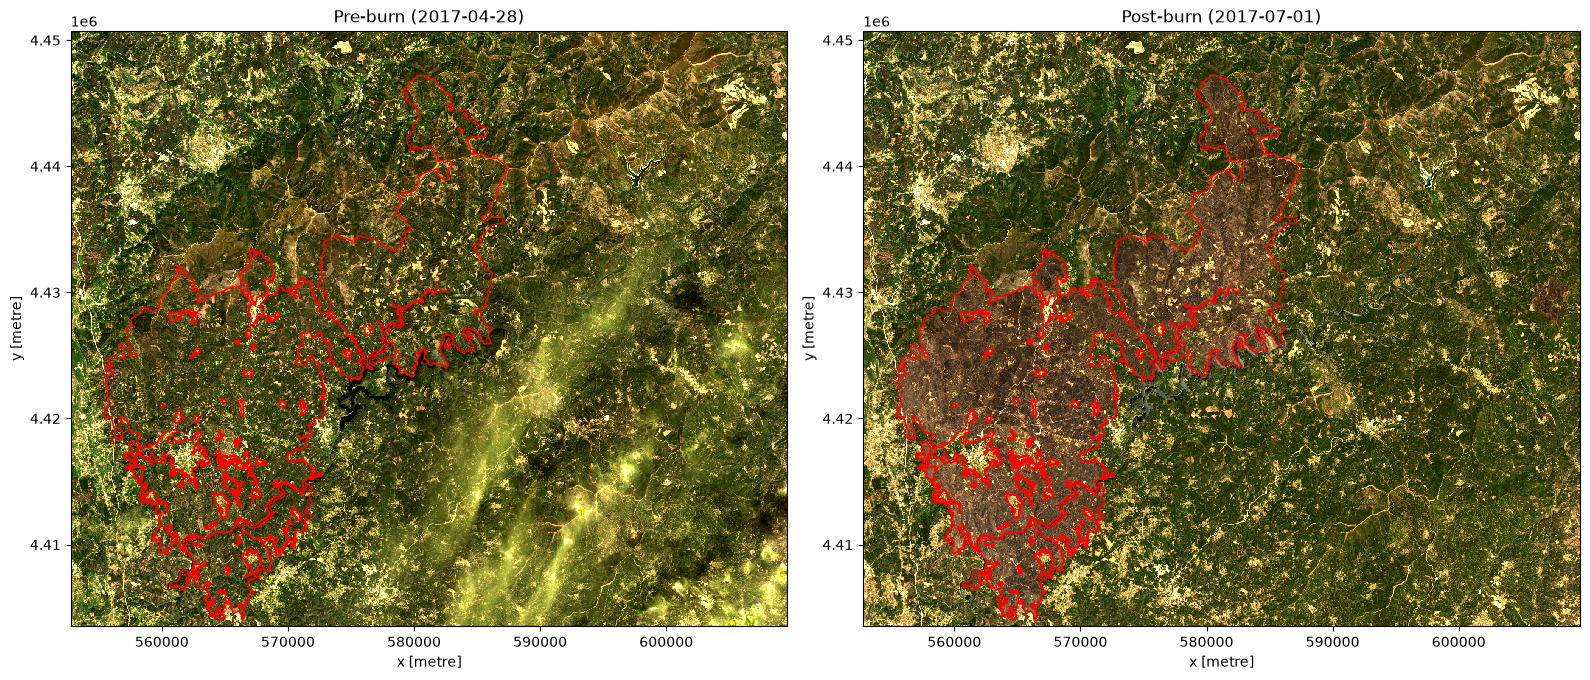

In [35]:
pre_fire = gdfs[0] # Rename for ease
post_fire = gdfs[1]
fp = gpd.read_file("../Data/selected_perimeters.gpkg") # Load the selected fire perimeters
pre_rgb = pre_fire.sel(band=["red", "green", "blue"]) # Select the red, green and blue bands
post_rgb = post_fire.sel(band=["red", "green", "blue"])


fig, axes = plt.subplots(1, 2, figsize=(16, 8))

pre_rgb.plot.imshow(
    ax=axes[0],
    rgb="band",
    robust=True
)

post_rgb.plot.imshow(
    ax=axes[1],
    rgb="band",
    robust=True
)

# Reproject perimeter to match raster
fp = fp.to_crs(pre_rgb.rio.crs)

# Overlay perimeter
fp.boundary.plot(
    ax=axes[0],
    color="red",
    linewidth=1
)

fp.boundary.plot(
    ax=axes[1],
    color="red",
    linewidth=1
)

axes[0].set_title("Pre-burn (2017-04-28)")
axes[1].set_title("Post-burn (2017-07-01)")

plt.tight_layout()
plt.show()

We can see that the perimeters match the affected area quite well. Next, we can calculate the NDVI and NBR for each image. 

In [36]:
pre_ndvi = ndvi(pre_fire)
post_ndvi = ndvi(post_fire)
pre_nbr = nbr(pre_fire)
post_nbr = nbr(post_fire)

And then we can plot before and after side by side for NDVI and then NBR.

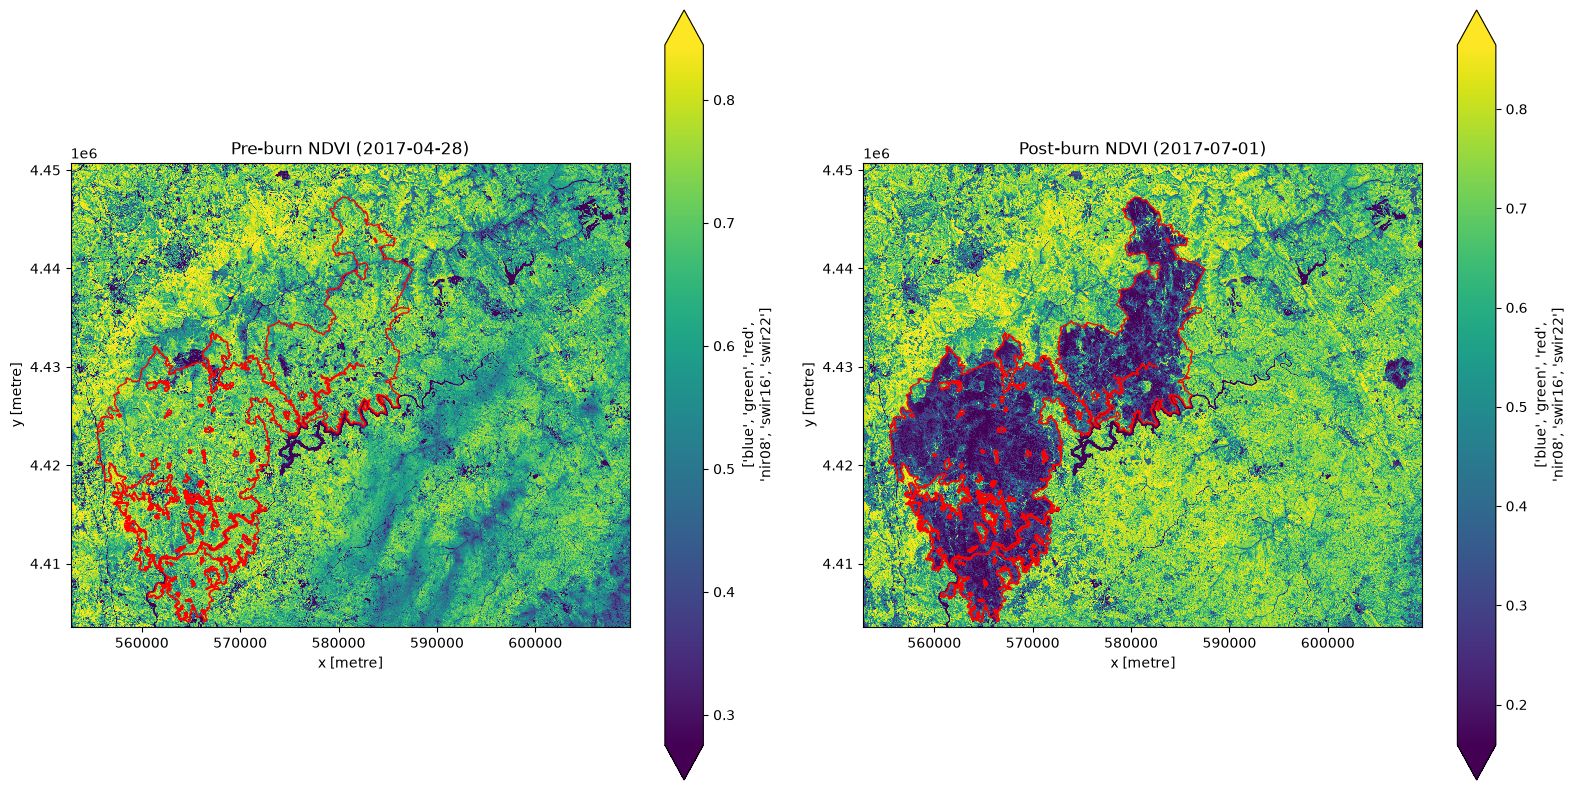

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

pre_ndvi.plot.imshow(
    ax=axes[0],
    robust=True
)

post_ndvi.plot.imshow(
    ax=axes[1],
    robust=True
)

# Overlay perimeter
fp.boundary.plot(
    ax=axes[0],
    color="red",
    linewidth=1
)

fp.boundary.plot(
    ax=axes[1],
    color="red",
    linewidth=1
)

axes[0].set_title("Pre-burn NDVI (2017-04-28)")
axes[1].set_title("Post-burn NDVI (2017-07-01)")

plt.tight_layout()
plt.show()

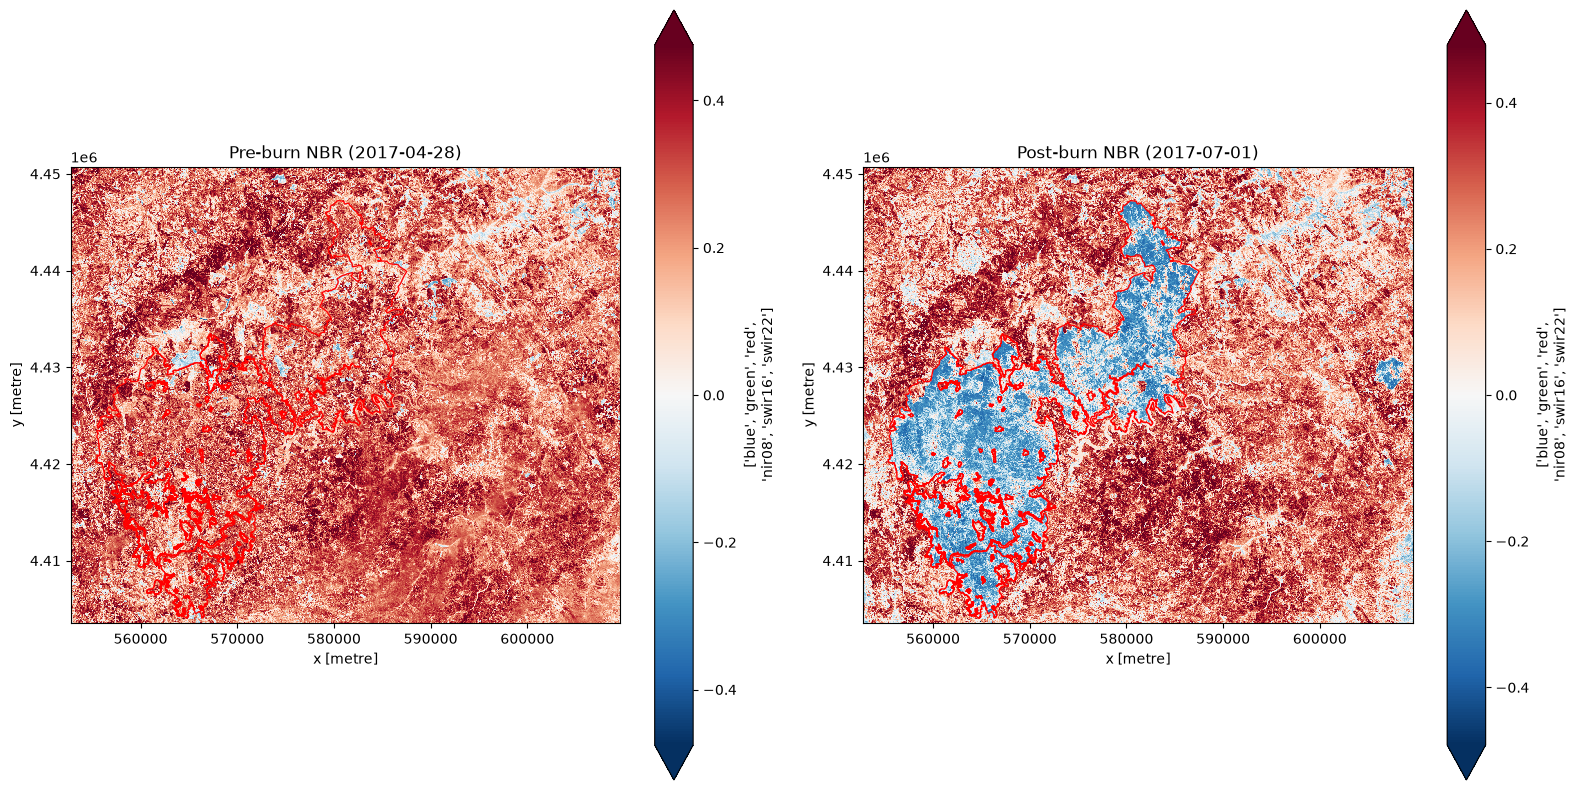

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

pre_nbr.plot.imshow(
    ax=axes[0],
    robust=True
)

post_nbr.plot.imshow(
    ax=axes[1],
    robust=True
)

# Overlay perimeter
fp.boundary.plot(
    ax=axes[0],
    color="red",
    linewidth=1
)

fp.boundary.plot(
    ax=axes[1],
    color="red",
    linewidth=1
)

axes[0].set_title("Pre-burn NBR (2017-04-28)")
axes[1].set_title("Post-burn NBR (2017-07-01)")

plt.tight_layout()
plt.show()

Additionally, we can compute the dNBR immediately after the fire to use as a benchmark/indicator for the initial disturbance caused by the fire. 

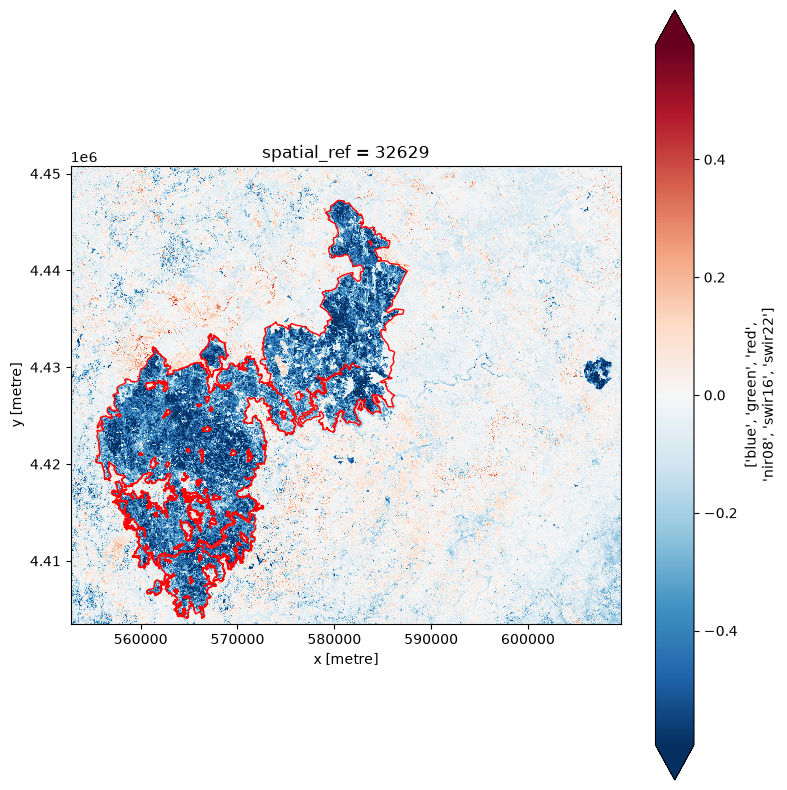

In [39]:
post_dnbr = post_nbr-pre_nbr # Calculate dNBR (difference of future NBR from initial NBR)

fig, ax = plt.subplots(1, 1, figsize=(8, 8))

post_dnbr.plot.imshow(
    ax=ax,
    robust=True
)

# Overlay perimeter
fp.boundary.plot(
    ax=ax,
    color="red",
    linewidth=1
)

axes[0].set_title("Immediate Post-fire dNBR (2017-07-01)")

plt.tight_layout()
plt.show()

By masking/clipping the data to inside the fire perimeters, we can calculate means (& sd, variance, etc) of the indexes to quantify and track damage and recovery.

In [40]:
pre_ndvi_clip = pre_ndvi.rio.clip(fp.geometry)
post_ndvi_clip = post_ndvi.rio.clip(fp.geometry)
pre_nbr_clip = pre_nbr.rio.clip(fp.geometry)
post_nbr_clip = post_nbr.rio.clip(fp.geometry)
post_dnbr_clip = post_dnbr.rio.clip(fp.geometry)

-0.37477660179138184


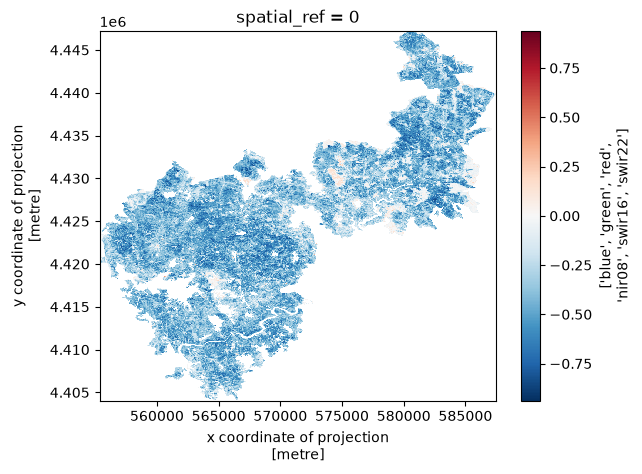

In [48]:
print(post_dnbr_clip.mean().item())
post_dnbr_clip.plot()

We can see the baseline disturbance can be quantified as a dNBR of -0.37 immediately after the fire. Lets look at the statistics of all the indices immediately before and after the fire. 

In [49]:
import numpy as np
import pandas as pd

indices = {
    "Pre-burn NDVI": pre_ndvi_clip,
    "Post-burn NDVI": post_ndvi_clip,
    "Pre-burn NBR": pre_nbr_clip,
    "Post-burn NBR": post_nbr_clip,
    "Post-burn dNBR": post_dnbr_clip
}

stats = {}

for name, da in indices.items():

    values = da.values.flatten()
    values = values[np.isfinite(values)]

    stats[name] = {
        "Count": len(values),
        "Mean": np.mean(values),
        "Median": np.median(values),
        "Std Dev": np.std(values),
        "Min": np.min(values),
        "25th percentile": np.percentile(values, 25),
        "75th percentile": np.percentile(values, 75),
        "Max": np.max(values)
    }

stats_df = pd.DataFrame(stats).T

print(stats_df.round(3))

                   Count   Mean  Median  Std Dev    Min  25th percentile  \
Pre-burn NDVI   533397.0  0.674   0.699    0.118 -0.014            0.621   
Post-burn NDVI  533397.0  0.303   0.262    0.142 -0.047            0.200   
Pre-burn NBR    533397.0  0.234   0.248    0.134 -0.295            0.152   
Post-burn NBR   533397.0 -0.140  -0.170    0.163 -0.474           -0.271   
Post-burn dNBR  533397.0 -0.375  -0.388    0.181 -0.938           -0.502   

                75th percentile    Max  
Pre-burn NDVI             0.754  0.956  
Post-burn NDVI            0.357  0.917  
Pre-burn NBR              0.331  0.632  
Post-burn NBR            -0.044  0.576  
Post-burn dNBR           -0.263  0.476  


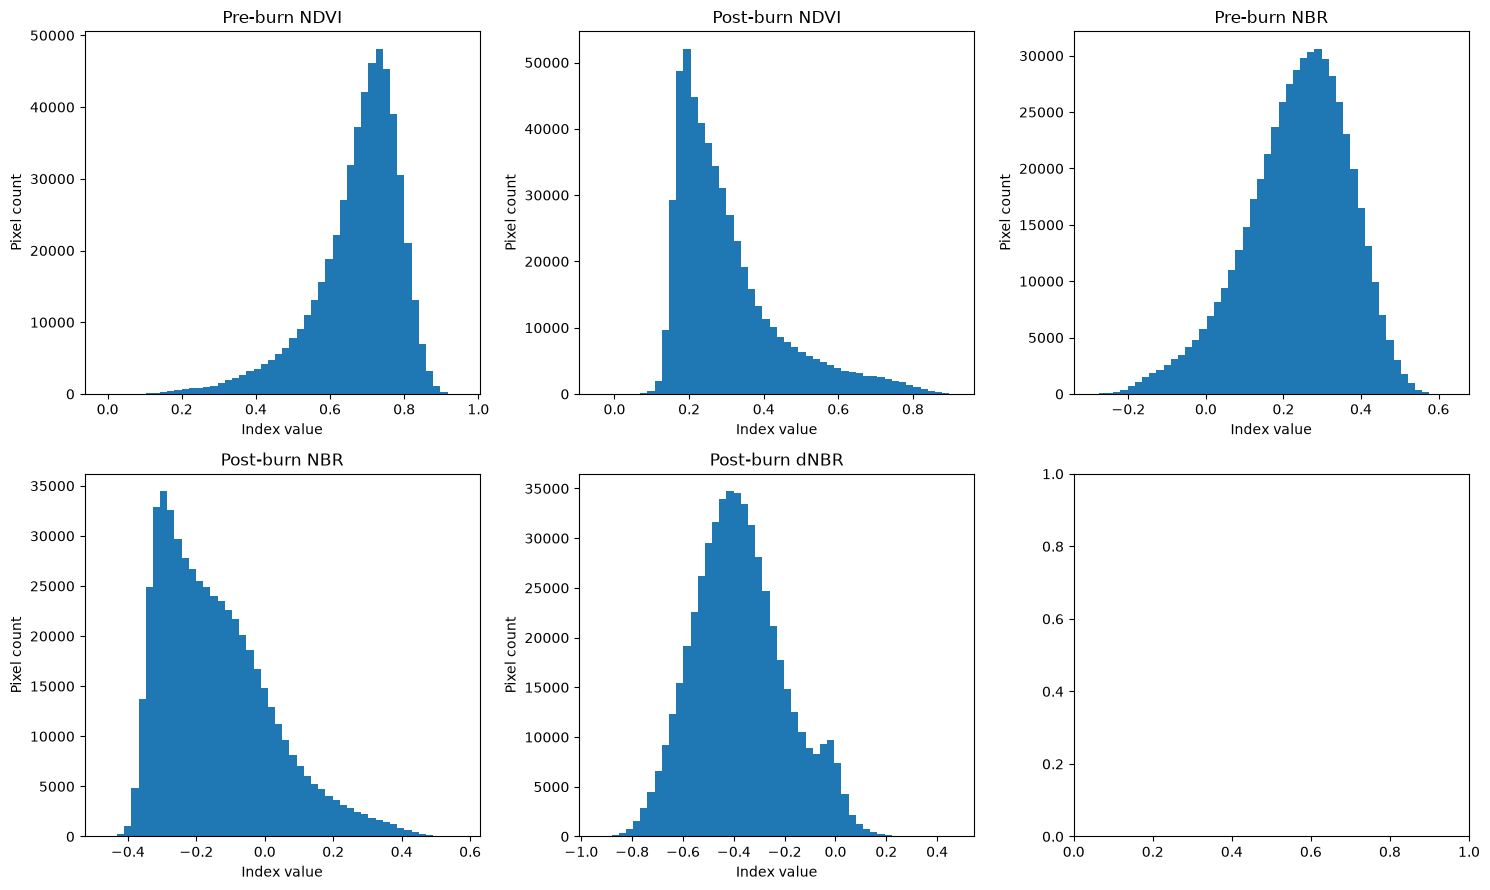

In [51]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, (name, da) in zip(axes.flatten(), indices.items()):

    values = da.values.flatten()
    values = values[np.isfinite(values)]

    ax.hist(values, bins=50)
    ax.set_title(name)
    ax.set_xlabel("Index value")
    ax.set_ylabel("Pixel count")

plt.tight_layout()
plt.show()